In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("nlp_field_observation_augmented.csv")
print(df.head())

                                         observation  score
0                             Dense and dry terrain.      4
1  The soil is acceptable firmness and partially ...      3
2  Foundations would sit on collapsing and no bea...      1
3            Observation: very hard and undisturbed.      5
4                                    Sinking ground.      1


In [3]:
df = df.sample(frac=1, random_state=42).reset_index(drop=True)


In [4]:
df.head()

,observation,score
0,Ground appears stable enough and stable enough.,3
1,Excavation reveals extremely dense layers.,5
2,Site consists of moderate stiffness material.,3
3,Excavation reveals fluid-like layers.,1
4,Foundations would sit on partially settled earth.,3


In [5]:
# Splitting input and output into X and y
X = df["observation"]  # text input
y = df["score"]        # target score (1–5)


# Doing train test split
from sklearn.model_selection import train_test_split

# X = text, y = scores
X_train, X_test, y_train, y_test = train_test_split(
    df["observation"], df["score"], 
    test_size=0.2,  # 20% for testing
    random_state=42
)


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1,2), # bigram
    max_features=1000   # limit features for Random Forest
)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

model = LinearSVC(
    C=2.0,
    class_weight='balanced',
    random_state=42,    
)

model.fit(X_train_tfidf, y_train)
# model = RandomForestClassifier(
#     n_estimators=300,
#     random_state=42
# )
# model.fit(X_train_tfidf, y_train)

y_pred = model.predict(X_test_tfidf)


Accuracy: 93.06 %

Classification Report:
              precision    recall  f1-score   support

           1       0.96      0.82      0.89        33
           2       0.88      0.98      0.93        46
           3       0.96      0.95      0.95        77
           4       0.91      0.91      0.91        35
           5       0.92      0.96      0.94        25

    accuracy                           0.93       216
   macro avg       0.93      0.92      0.92       216
weighted avg       0.93      0.93      0.93       216



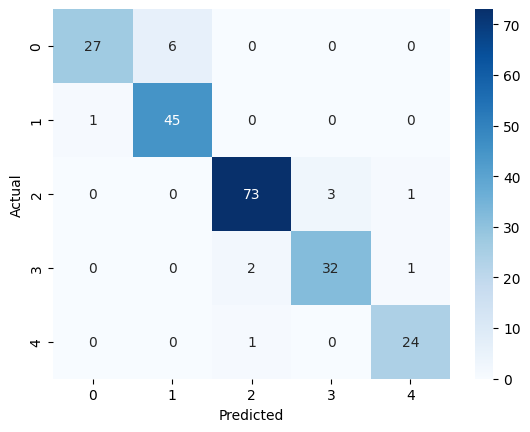

In [8]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Simple accuracy
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", round(acc*100, 2), "%")

# Detailed report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Optional: Confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [9]:
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Load data
df = pd.read_csv("nlp_field_observation_augmented.csv")

# Shuffle
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

X = df["observation"]
y = df["score"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Create pipeline
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=1000
    )),
    ("classifier", LinearSVC(
        C=2.0,
        class_weight="balanced",
        random_state=42
    ))
])

# Train
pipeline.fit(X_train, y_train)

# Evaluate
y_pred = pipeline.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print(classification_report(y_test, y_pred))

import joblib

joblib.dump(pipeline,"nlp_model.pkl")


Accuracy: 93.06 %
              precision    recall  f1-score   support

           1       0.96      0.82      0.89        33
           2       0.88      0.98      0.93        46
           3       0.96      0.95      0.95        77
           4       0.91      0.91      0.91        35
           5       0.92      0.96      0.94        25

    accuracy                           0.93       216
   macro avg       0.93      0.92      0.92       216
weighted avg       0.93      0.93      0.93       216



['nlp_model.pkl']